### Exercise 1

Moving-average crossover. Implement a fast/slow SMA crossover (e.g. 50/200) on an index ETF over 15+ years. Long when fast > slow, flat otherwise. Enforce no look-ahead (the position on day t uses averages through t−1). Report net-of-cost performance versus buy-and-hold, and report the number of trades and total cost paid. 

Stretch: sweep the fast/slow window pair over a grid and plot the Sharpe ratio surface. Then split the sample in half, select the best pair on the first half only, and evaluate it once on the second half. Report how far the out-of-sample Sharpe falls below the in-sample best.

#### Report

Methodology. I tested a 50/200-day simple moving-average crossover on SPY from 2005 to 2025. The strategy held SPY when the 50-day average was above the 200-day average and held cash otherwise. I compared the results to a benchmark, which was buying and holding the stock. Both portfolios started with $10,000. I assumed a 0.10% fee for each buy and sell, with cash earning 0 interest.

The results suggest that the buy-and-hold strategy achieved a significantly higher total return of 732.46%, compared with 434.60% for the SMA strategy. However, the moving-average strategy achieved a slightly higher Sharpe ratio (0.68 vs 0.64), suggesting better risk adjusted performance. The most important difference was the maximum drawdown. The SMA strategy experienced a maximum decline of 32.05%, compared with 55.42% for the buy-and-hold. This suggests that the MA strategy helped reduce exposure during major market downturns.

To find the best moving-average combination, we tested 41 different strategies using six fast SMA windows (10, 20, 30, 50, 75, and 100 days) and seven slow SMA windows (100, 125, 150, 175, 200, 225, and 250 days). We divided the dataset into two periods. The first period (2005–2015) was used to find the strategy with the highest Sharpe ratio, while the second period (2015–2025) was used to test its performance on unseen data. The best combination was 30/200 SMA, which achieved an in-sample Sharpe ratio of 0.895. However, when tested on the second period, its Sharpe ratio decreased to 0.592, representing a decline of 0.304.

Full sample (dates of entry opens): 2005-01-03 to 2025-12-30
                  Total return (%)  Annualized return (%)  Sharpe  Max drawdown (%)  Trades  Fees paid ($)
50/200 SMA                  434.60                   8.33    0.68            -32.05   21.00         475.87
Buy and hold SPY            732.46                  10.64    0.64            -55.42    1.00           9.99

In sample: 2005-01-03 to 2015-06-29
Out of sample: 2015-07-01 to 2025-12-30
Best training pair: 30/200
In-sample Sharpe:     0.895
Out-of-sample Sharpe: 0.592
Sharpe drop (negative means improvement): 0.304


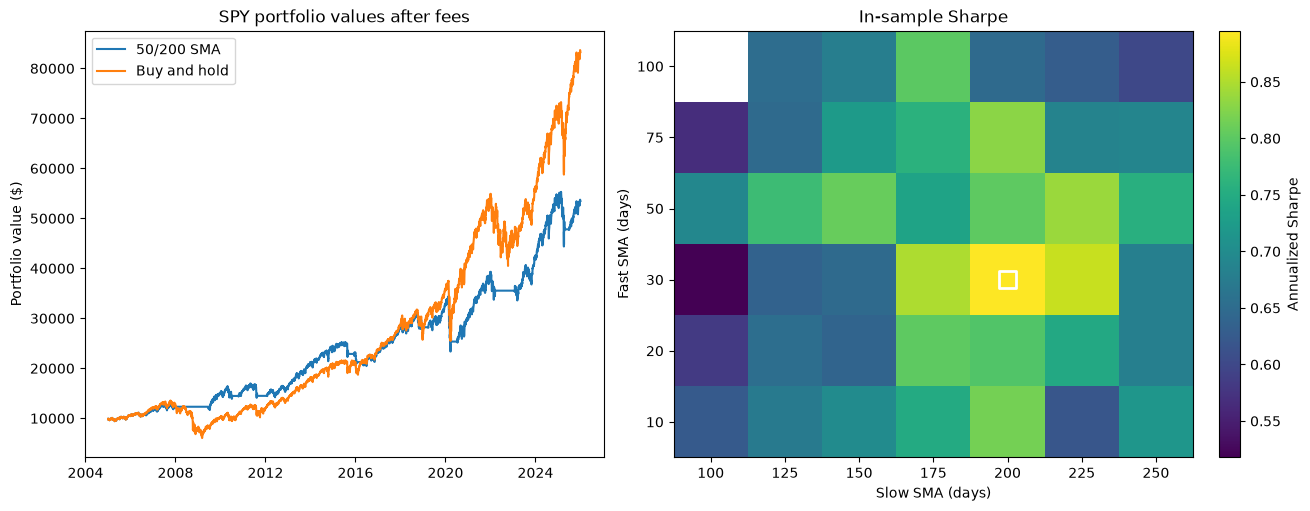

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

TICKER = "SPY"
START = "2004-01-01"  # Extra history for the moving averages
END = "2026-01-01"    # Exclusive download end date
EVALUATION_START = "2005-01-01"
INITIAL_CAPITAL = 10_000
TRADE_COST = 0.001    # 0.10% of the dollar amount bought or sold
TRADING_DAYS = 252
FAST_WINDOWS = [10, 20, 30, 50, 75, 100]
SLOW_WINDOWS = [100, 125, 150, 175, 200, 225, 250]


def crossover_position(close, fast, slow):
    fast_sma = close.rolling(fast).mean()
    slow_sma = close.rolling(slow).mean()
    signal = fast_sma.gt(slow_sma).where(slow_sma.notna())
    # Today's trade at the open uses averages through yesterday's close.
    return signal.shift(1)


def backtest(asset_return, position):
    # Each run starts in cash. A change in position is one buy or one sell.
    previous = position.shift(1, fill_value=0)
    buys = position.eq(1) & previous.eq(0)
    sells = position.eq(0) & previous.eq(1)
    trades = buys | sells

    # On a buy, shares plus the fee must fit within available cash.
    fee_fraction = buys * (TRADE_COST / (1 + TRADE_COST)) + sells * TRADE_COST
    gross_return = position * asset_return  # Cash earns 0%.
    net_return = (1 - fee_fraction) * (1 + gross_return) - 1
    equity = INITIAL_CAPITAL * (1 + net_return).cumprod()
    fees = equity.shift(1, fill_value=INITIAL_CAPITAL) * fee_fraction

    return pd.DataFrame({
        "net_return": net_return,
        "equity": equity,
        "trade": trades,
        "fee": fees,
    })


def sharpe(returns):
    volatility = returns.std()
    return np.sqrt(TRADING_DAYS) * returns.mean() / volatility if volatility > 0 else np.nan


def summarize(result):
    equity = result["equity"]
    peak = equity.cummax().clip(lower=INITIAL_CAPITAL)
    return {
        "Total return (%)": 100 * (equity.iloc[-1] / INITIAL_CAPITAL - 1),
        "Annualized return (%)": 100 * (
            (equity.iloc[-1] / INITIAL_CAPITAL) ** (TRADING_DAYS / len(equity)) - 1
        ),
        "Sharpe": sharpe(result["net_return"]),  # Assumes a 0% risk-free rate
        "Max drawdown (%)": 100 * (equity / peak - 1).min(),
        "Trades": int(result["trade"].sum()),
        "Fees paid ($)": result["fee"].sum(),
    }


def main():
    prices = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
    if prices.empty:
        raise RuntimeError(f"No prices downloaded for {TICKER}. Check the connection and retry.")
    # Supports both single-level and single-ticker MultiIndex download columns.
    open_price = prices["Open"].squeeze()
    close = prices["Close"].squeeze()
    prices = pd.DataFrame({"open": open_price, "close": close}).dropna().sort_index()
    close = prices["close"]

    # A position opened today earns the return from today's open to the next open.
    # The next open is used only for measuring the return.
    asset_return = (prices["open"].shift(-1) / prices["open"] - 1).dropna()
    longest_slow = max(200, max(SLOW_WINDOWS))
    ready = close.rolling(longest_slow).mean().shift(1).notna()
    asset_return = asset_return.loc[EVALUATION_START:]
    asset_return = asset_return.loc[ready.reindex(asset_return.index)]
    if len(asset_return) < 15 * TRADING_DAYS:
        raise RuntimeError("The download did not provide 15 years of usable daily returns.")

    base_position = crossover_position(close, 50, 200).loc[asset_return.index]
    strategy = backtest(asset_return, base_position)
    buy_and_hold = backtest(asset_return, pd.Series(1, index=asset_return.index))

    full_summary = pd.DataFrame({
        "50/200 SMA": summarize(strategy),
        f"Buy and hold {TICKER}": summarize(buy_and_hold),
    }).T
    print(f"Full sample (dates of entry opens): {asset_return.index[0].date()} to "
          f"{asset_return.index[-1].date()}")
    print(full_summary.to_string(float_format=lambda value: f"{value:.2f}"))

    # Give every pair the same dates. Earlier closes provide the SMA warm-up.
    split = len(asset_return) // 2
    # Omit the interval ending at the first test open so selection is ready before it.
    train_returns = asset_return.iloc[:split - 1]
    test_returns = asset_return.iloc[split:]
    train_close = close.loc[:train_returns.index[-1]]
    scores = pd.DataFrame(np.nan, index=FAST_WINDOWS, columns=SLOW_WINDOWS)
    for fast in FAST_WINDOWS:
        for slow in SLOW_WINDOWS:
            if fast < slow:
                position = crossover_position(train_close, fast, slow).loc[train_returns.index]
                result = backtest(train_returns, position)
                scores.loc[fast, slow] = sharpe(result["net_return"])

    best_fast, best_slow = scores.stack().idxmax()
    train_sharpe = scores.loc[best_fast, best_slow]

    # Start the test portfolio in cash and charge for any initial entry.
    test_position = crossover_position(close, best_fast, best_slow).loc[test_returns.index]
    test_result = backtest(test_returns, test_position)
    test_sharpe = sharpe(test_result["net_return"])
    print(f"\nIn sample: {train_returns.index[0].date()} to {train_returns.index[-1].date()}")
    print(f"Out of sample: {test_returns.index[0].date()} to {test_returns.index[-1].date()}")
    print(f"Best training pair: {best_fast}/{best_slow}")
    print(f"In-sample Sharpe:     {train_sharpe:.3f}")
    print(f"Out-of-sample Sharpe: {test_sharpe:.3f}")
    print(f"Sharpe drop (negative means improvement): {train_sharpe - test_sharpe:.3f}")

    # Equity is marked at the next open, so plot it on that date.
    next_open_date = prices.index.to_series().shift(-1).loc[asset_return.index]
    fig, (ax_equity, ax_sharpe) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
    ax_equity.plot(next_open_date, strategy["equity"], label="50/200 SMA")
    ax_equity.plot(next_open_date, buy_and_hold["equity"], label="Buy and hold")
    ax_equity.set(title=f"{TICKER} portfolio values after fees", ylabel="Portfolio value ($)")
    ax_equity.legend()

    heatmap = ax_sharpe.imshow(scores, aspect="auto", origin="lower", cmap="viridis")
    ax_sharpe.set_xticks(range(len(SLOW_WINDOWS)), SLOW_WINDOWS)
    ax_sharpe.set_yticks(range(len(FAST_WINDOWS)), FAST_WINDOWS)
    ax_sharpe.set(title="In-sample Sharpe", xlabel="Slow SMA (days)", ylabel="Fast SMA (days)")
    ax_sharpe.scatter(SLOW_WINDOWS.index(best_slow), FAST_WINDOWS.index(best_fast),
                      marker="s", s=150, facecolors="none", edgecolors="white", linewidths=2)
    fig.colorbar(heatmap, ax=ax_sharpe, label="Annualized Sharpe")
    plt.show()


if __name__ == "__main__":
    main()
